<a href="https://colab.research.google.com/github/Pavanprasad1/fake-job-detection/blob/main/fake_job_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files
uploaded = files.upload()  # A button will appear — click it and select your CSV

Saving fake_job_postings.csv to fake_job_postings.csv


In [3]:
# Install any missing packages
!pip install wordcloud -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import re
warnings.filterwarnings('ignore')

from wordcloud import WordCloud
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_curve, auc, roc_auc_score
)
from sklearn.pipeline import Pipeline

print("✅ All libraries loaded successfully!")

✅ All libraries loaded successfully!


In [4]:
df = pd.read_csv('fake_job_postings.csv')

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst look:")
df.head(3)

Shape: (17880, 18)

Columns: ['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

First look:


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


In [5]:
print("=" * 50)
print("DATASET OVERVIEW")
print("=" * 50)

print(f"\nTotal job postings: {len(df)}")
print(f"Legitimate jobs:    {(df['fraudulent'] == 0).sum()}")
print(f"Fraudulent jobs:    {(df['fraudulent'] == 1).sum()}")
print(f"Fraud percentage:   {df['fraudulent'].mean()*100:.1f}%")

print("\n--- Missing Values ---")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage': missing_pct})
print(missing_df[missing_df['Missing Count'] > 0])

print("\n--- Data Types ---")
print(df.dtypes)

DATASET OVERVIEW

Total job postings: 17880
Legitimate jobs:    17014
Fraudulent jobs:    866
Fraud percentage:   4.8%

--- Missing Values ---
                     Missing Count  Percentage
location                       346         1.9
department                   11547        64.6
salary_range                 15012        84.0
company_profile               3308        18.5
description                      1         0.0
requirements                  2696        15.1
benefits                      7212        40.3
employment_type               3471        19.4
required_experience           7050        39.4
required_education            8105        45.3
industry                      4903        27.4
function                      6455        36.1

--- Data Types ---
job_id                  int64
title                  object
location               object
department             object
salary_range           object
company_profile        object
description            object
requirements    

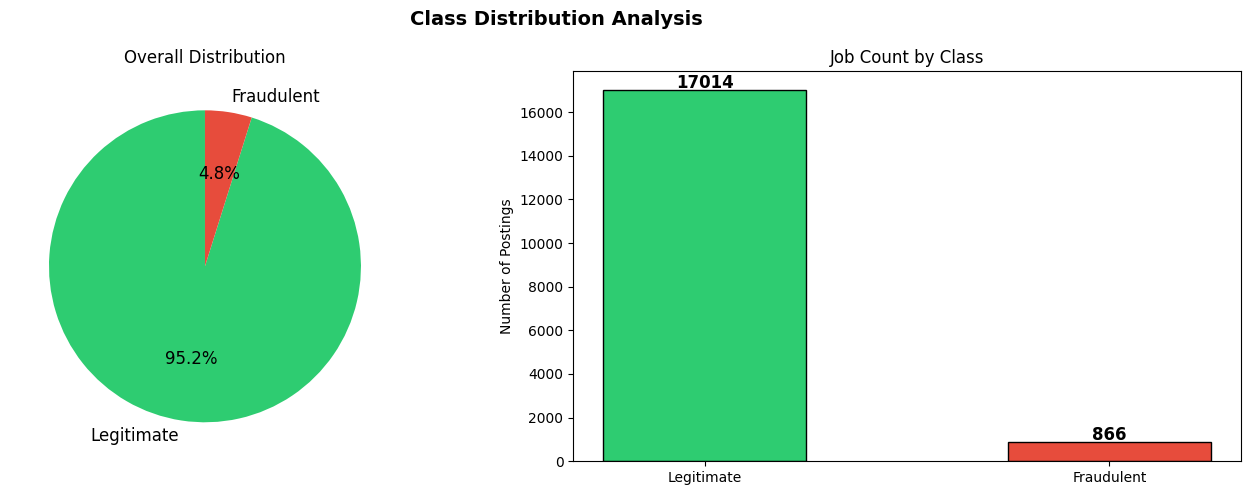

✅ Class distribution plotted!


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Class Distribution Analysis', fontsize=14, fontweight='bold')

# Pie chart
sizes = df['fraudulent'].value_counts()
colors = ['#2ecc71', '#e74c3c']
axes[0].pie(sizes, labels=['Legitimate', 'Fraudulent'],
            colors=colors, autopct='%1.1f%%', startangle=90,
            textprops={'fontsize': 12})
axes[0].set_title('Overall Distribution')

# Count bar
axes[1].bar(['Legitimate', 'Fraudulent'], sizes.values, color=colors, edgecolor='black', width=0.5)
axes[1].set_title('Job Count by Class')
axes[1].set_ylabel('Number of Postings')
for i, v in enumerate(sizes.values):
    axes[1].text(i, v + 100, str(v), ha='center', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()
print("✅ Class distribution plotted!")

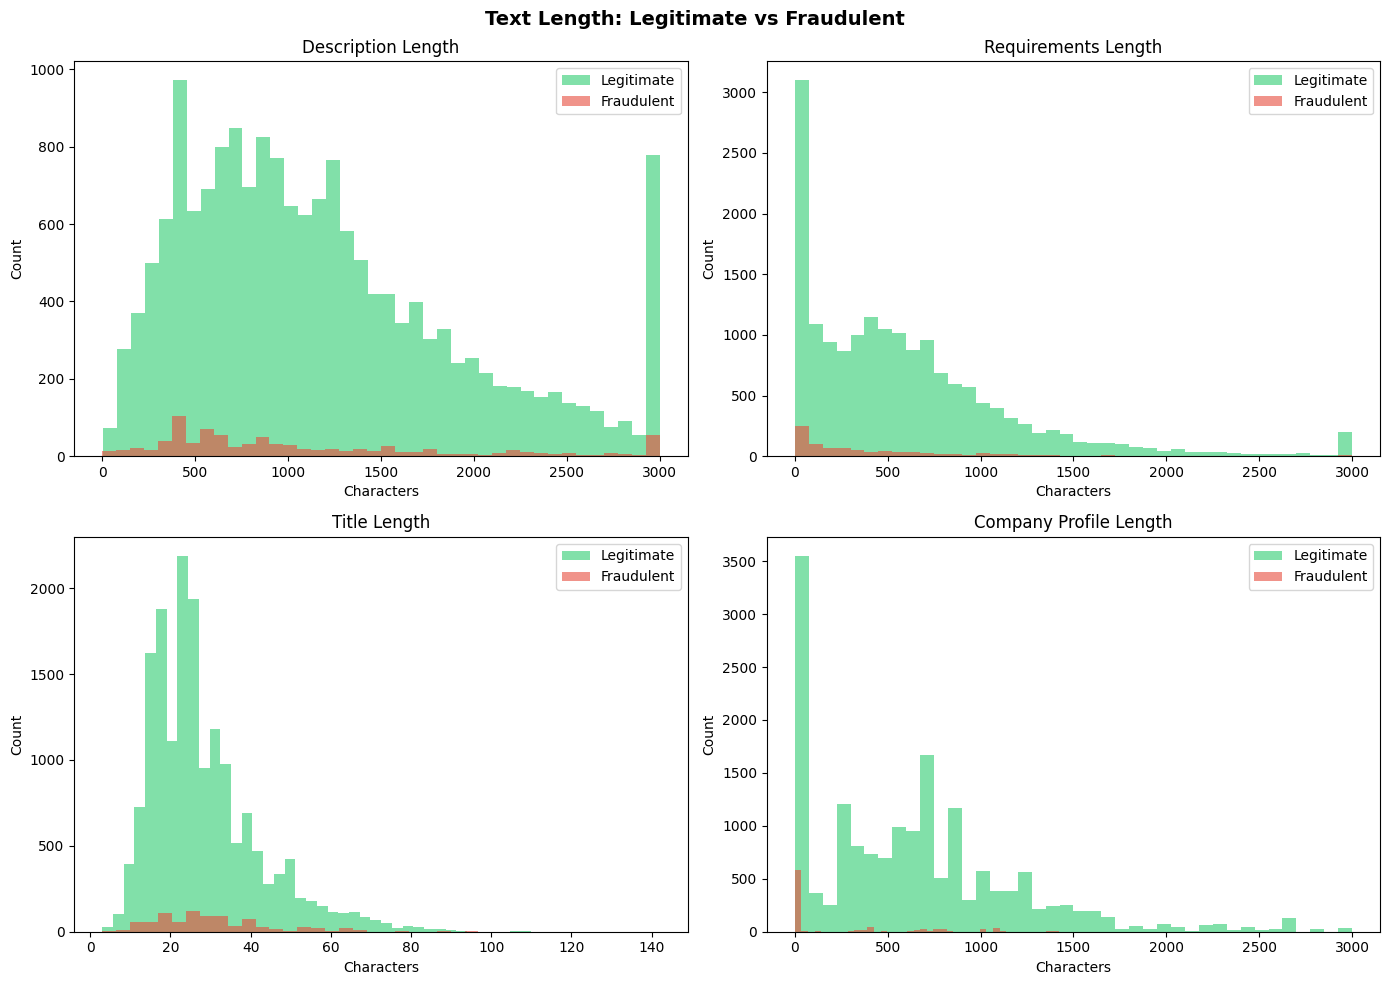

Average Text Lengths:
Feature                     Legitimate   Fraudulent
--------------------------------------------------
Description Length                1221         1155
Requirements Length                597          446
Title Length                        28           31
Company Profile Length             641          231

✅ Text length analysis done!


In [7]:
# Fill missing text columns with empty string
text_cols = ['title', 'company_profile', 'description', 'requirements', 'benefits']
for col in text_cols:
    df[col] = df[col].fillna('')

# Add text length features
df['desc_len']    = df['description'].apply(len)
df['req_len']     = df['requirements'].apply(len)
df['title_len']   = df['title'].apply(len)
df['profile_len'] = df['company_profile'].apply(len)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Text Length: Legitimate vs Fraudulent', fontsize=14, fontweight='bold')

cols    = ['desc_len', 'req_len', 'title_len', 'profile_len']
titles  = ['Description Length', 'Requirements Length', 'Title Length', 'Company Profile Length']
colors  = [('#2ecc71', '#e74c3c')]* 4

for i, (col, title) in enumerate(zip(cols, titles)):
    ax = axes[i // 2][i % 2]
    real_vals = df[df.fraudulent == 0][col].clip(0, 3000)
    fake_vals = df[df.fraudulent == 1][col].clip(0, 3000)
    ax.hist(real_vals, bins=40, color='#2ecc71', alpha=0.6, label='Legitimate')
    ax.hist(fake_vals, bins=40, color='#e74c3c', alpha=0.6, label='Fraudulent')
    ax.set_title(title)
    ax.set_xlabel('Characters')
    ax.set_ylabel('Count')
    ax.legend()

plt.tight_layout()
plt.show()

# Print average lengths
print("Average Text Lengths:")
print(f"{'Feature':<25} {'Legitimate':>12} {'Fraudulent':>12}")
print("-" * 50)
for col, title in zip(cols, titles):
    real_avg = df[df.fraudulent==0][col].mean()
    fake_avg = df[df.fraudulent==1][col].mean()
    print(f"{title:<25} {real_avg:>12.0f} {fake_avg:>12.0f}")

print("\n✅ Text length analysis done!")

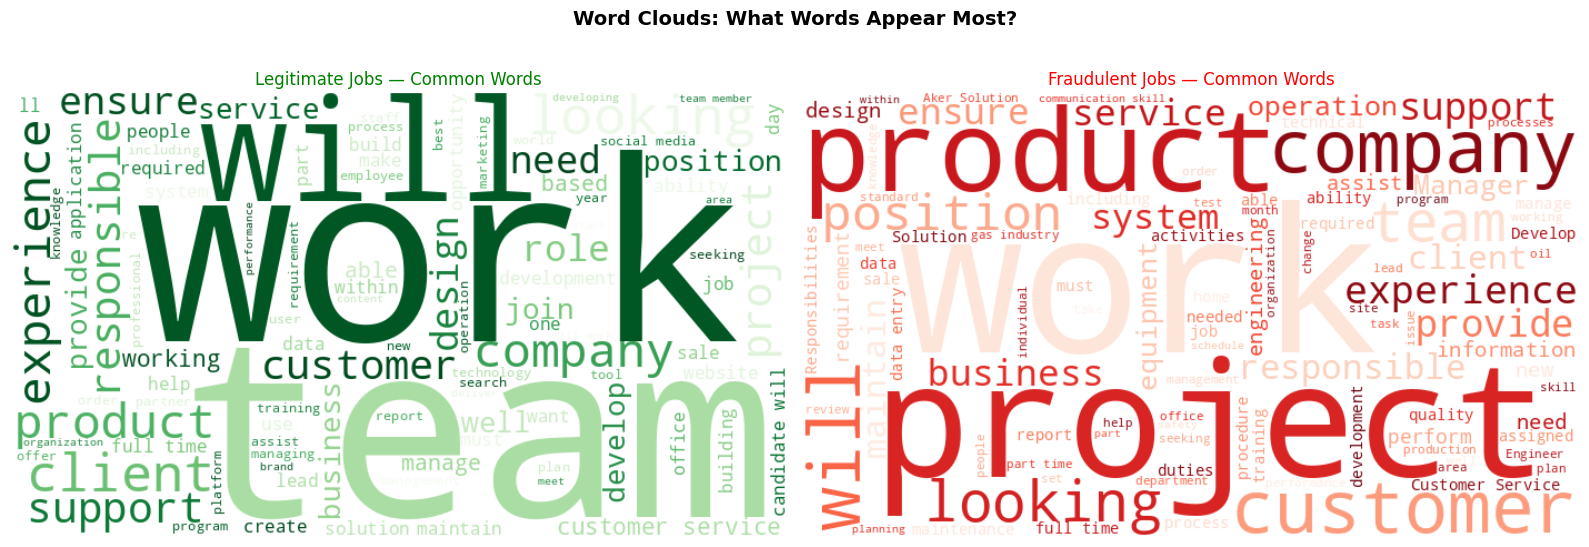

✅ Word clouds generated!


In [8]:
from wordcloud import WordCloud

real_text = ' '.join(df[df.fraudulent == 0]['description'].tolist())
fake_text = ' '.join(df[df.fraudulent == 1]['description'].tolist())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Word Clouds: What Words Appear Most?', fontsize=14, fontweight='bold')

wc_real = WordCloud(width=700, height=400, background_color='white',
                    colormap='Greens', max_words=100).generate(real_text)
wc_fake = WordCloud(width=700, height=400, background_color='white',
                    colormap='Reds', max_words=100).generate(fake_text)

axes[0].imshow(wc_real, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Legitimate Jobs — Common Words', fontsize=12, color='green')

axes[1].imshow(wc_fake, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Fraudulent Jobs — Common Words', fontsize=12, color='red')

plt.tight_layout()
plt.show()
print("✅ Word clouds generated!")

In [9]:
import re

def clean_text(text):
    if pd.isna(text) or text == '':
        return ''
    text = str(text).lower()                        # lowercase
    text = re.sub(r'http\S+|www\S+', '', text)      # remove URLs
    text = re.sub(r'\S+@\S+', '', text)             # remove emails
    text = re.sub(r'[^a-z0-9\s]', ' ', text)        # remove special chars
    text = re.sub(r'\s+', ' ', text).strip()         # remove extra spaces
    return text

# Combine all text columns into one powerful feature
df['combined_text'] = (
    df['title'] + ' ' +
    df['company_profile'] + ' ' +
    df['description'] + ' ' +
    df['requirements'] + ' ' +
    df['benefits']
)

# Clean the combined text
df['combined_text_clean'] = df['combined_text'].apply(clean_text)

# Verify
print("Sample BEFORE cleaning:")
print(df['combined_text'].iloc[0][:300])
print("\nSample AFTER cleaning:")
print(df['combined_text_clean'].iloc[0][:300])
print(f"\nTotal samples ready: {len(df)}")
print("✅ Text preprocessing done!")

Sample BEFORE cleaning:
Marketing Intern We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and 

Sample AFTER cleaning:
marketing intern we re food52 and we ve created a groundbreaking and award winning cooking site we support connect and celebrate home cooks and give them everything they need in one place we have a top editorial business and engineering team we re focused on using technology to find new and better w

Total samples ready: 17880
✅ Text preprocessing done!


In [10]:
X = df['combined_text_clean']
y = df['fraudulent']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y        # keeps same fraud % in both splits
)

print("Dataset Split:")
print(f"  Training samples : {len(X_train)}")
print(f"  Testing samples  : {len(X_test)}")
print(f"\nFraud in training : {y_train.sum()} ({y_train.mean()*100:.1f}%)")
print(f"Fraud in testing  : {y_test.sum()} ({y_test.mean()*100:.1f}%)")
print("\n✅ Train/test split done!")

Dataset Split:
  Training samples : 14304
  Testing samples  : 3576

Fraud in training : 693 (4.8%)
Fraud in testing  : 173 (4.8%)

✅ Train/test split done!


In [11]:
# TF-IDF Vectorizer - converts text to numbers
tfidf = TfidfVectorizer(
    max_features=10000,      # top 10,000 words
    ngram_range=(1, 2),      # single words + pairs (e.g. "work from home")
    sublinear_tf=True,       # reduces impact of very frequent words
    stop_words='english'     # removes "the", "is", "and" etc.
)

# CountVectorizer - simpler word count approach
count_vec = CountVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words='english'
)

# Fit on training data, transform both train and test
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

X_train_count = count_vec.fit_transform(X_train)
X_test_count  = count_vec.transform(X_test)

print("Feature Extraction Complete!")
print(f"  TF-IDF matrix shape  : {X_train_tfidf.shape}")
print(f"  Count matrix shape   : {X_train_count.shape}")

# Show top 20 most important words
feature_names = tfidf.get_feature_names_out()
print(f"\nSample TF-IDF features (first 20):")
print(list(feature_names[:20]))
print("\n✅ Feature extraction done!")

Feature Extraction Complete!
  TF-IDF matrix shape  : (14304, 10000)
  Count matrix shape   : (14304, 10000)

Sample TF-IDF features (first 20):
['00', '00 00', '00 hour', '00 pm', '000', '000 people', '00am', '01a736d89d2f0b19de700923d2c312837e180465650804d0f84105352812bf9a', '0fa3f7c5e23a16de16a841e368006cae916884407d90b154dfef3976483a71ae', '0fa3f7c5e23a16de16a841e368006cae916884407d90b154dfef3976483a71ae information', '0in', '0in 4pt', '0in mso', '0pt', '0pt font', '10', '10 00', '10 000', '10 0pt', '10 years']

✅ Feature extraction done!


In [12]:
# Define all models to compare
models = {
    "Logistic Regression (TF-IDF)"  : (LogisticRegression(max_iter=1000, C=1.0), X_train_tfidf, X_test_tfidf),
    "Naive Bayes (TF-IDF)"          : (MultinomialNB(alpha=0.1),                 X_train_tfidf, X_test_tfidf),
    "Complement NB (TF-IDF)"        : (ComplementNB(alpha=0.1),                  X_train_tfidf, X_test_tfidf),
    "Linear SVM (TF-IDF)"           : (LinearSVC(max_iter=2000),                 X_train_tfidf, X_test_tfidf),
    "Logistic Regression (Count)"   : (LogisticRegression(max_iter=1000),        X_train_count, X_test_count),
    "Naive Bayes (Count)"           : (MultinomialNB(),                          X_train_count, X_test_count),
}

results = []

print(f"{'Model':<35} {'Acc':>6} {'Prec':>6} {'Recall':>6} {'F1':>6}")
print("-" * 60)

for name, (model, X_tr, X_te) in models.items():
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        'name': name, 'model': model,
        'acc': acc, 'precision': prec,
        'recall': rec, 'f1': f1,
        'y_pred': y_pred,
        'X_test': X_te
    })
    print(f"{name:<35} {acc:>6.3f} {prec:>6.3f} {rec:>6.3f} {f1:>6.3f}")

best = max(results, key=lambda x: x['f1'])
print(f"\n🏆 Best Model: {best['name']} (F1 = {best['f1']:.3f})")
print("\n✅ All models trained!")

Model                                  Acc   Prec Recall     F1
------------------------------------------------------------
Logistic Regression (TF-IDF)         0.974  1.000  0.468  0.638
Naive Bayes (TF-IDF)                 0.978  0.843  0.682  0.754
Complement NB (TF-IDF)               0.907  0.335  0.942  0.495
Linear SVM (TF-IDF)                  0.988  0.992  0.751  0.855
Logistic Regression (Count)          0.987  0.950  0.763  0.846
Naive Bayes (Count)                  0.919  0.364  0.913  0.521

🏆 Best Model: Linear SVM (TF-IDF) (F1 = 0.855)

✅ All models trained!


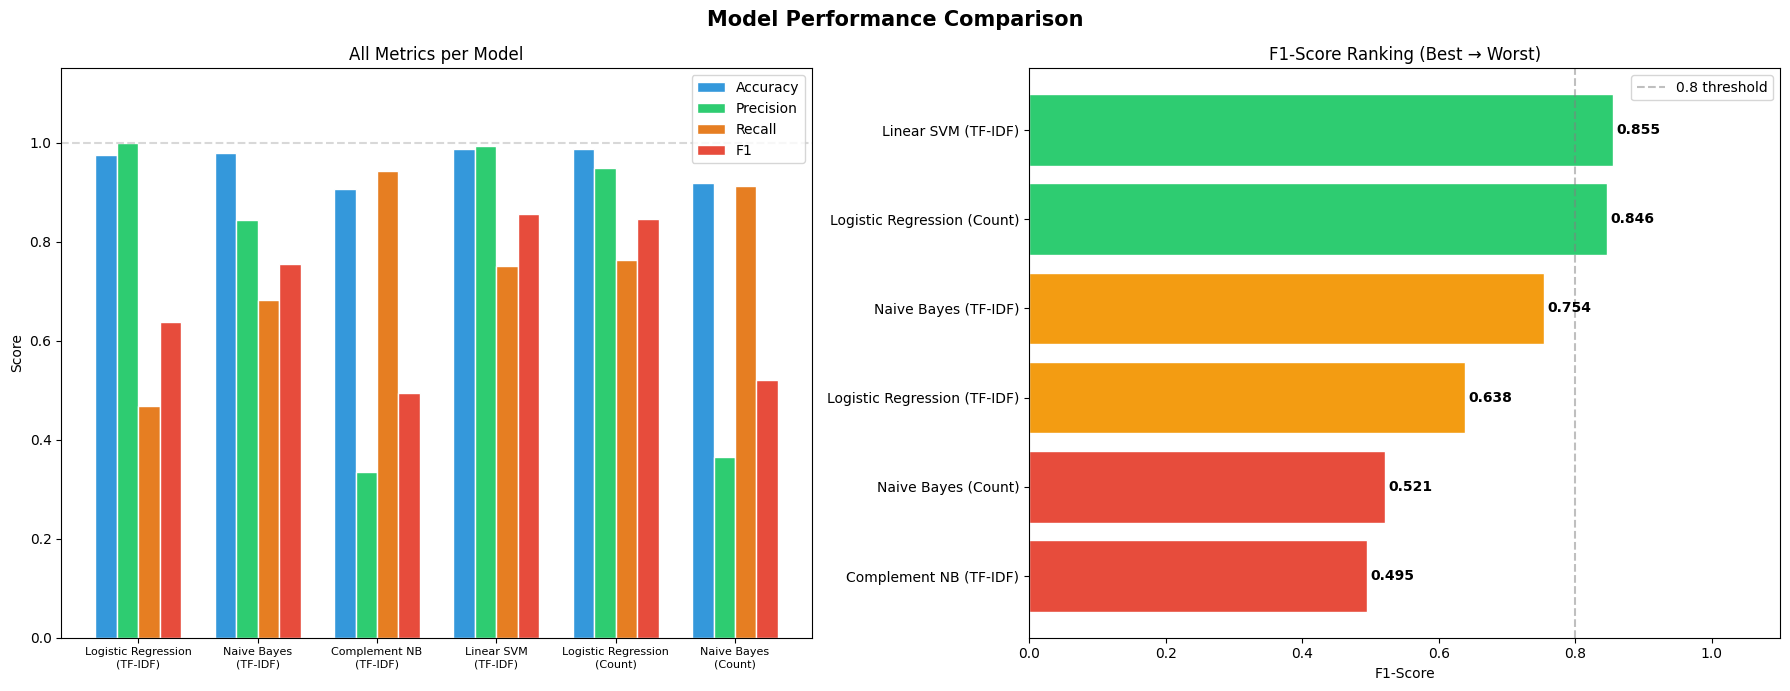

✅ Model comparison chart done!


In [13]:
results_df = pd.DataFrame([{
    'Model'    : r['name'],
    'Accuracy' : r['acc'],
    'Precision': r['precision'],
    'Recall'   : r['recall'],
    'F1'       : r['f1']
} for r in results])

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Model Performance Comparison', fontsize=15, fontweight='bold')

# --- Left: All metrics grouped bar ---
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
colors  = ['#3498db', '#2ecc71', '#e67e22', '#e74c3c']
x       = np.arange(len(results_df))
width   = 0.18

for i, (metric, color) in enumerate(zip(metrics, colors)):
    axes[0].bar(x + i * width, results_df[metric],
                width, label=metric, color=color, edgecolor='white')

axes[0].set_xticks(x + width * 1.5)
axes[0].set_xticklabels(
    [n.replace(' (TF-IDF)', '\n(TF-IDF)').replace(' (Count)', '\n(Count)')
     for n in results_df['Model']],
    fontsize=8
)
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel('Score')
axes[0].set_title('All Metrics per Model')
axes[0].legend()
axes[0].axhline(y=1.0, color='gray', linestyle='--', alpha=0.3)

# --- Right: F1 horizontal ranking ---
sorted_df = results_df.sort_values('F1')
bar_colors = ['#e74c3c' if f < 0.6 else '#f39c12' if f < 0.8 else '#2ecc71'
              for f in sorted_df['F1']]

bars = axes[1].barh(sorted_df['Model'], sorted_df['F1'],
                    color=bar_colors, edgecolor='white')
for bar, val in zip(bars, sorted_df['F1']):
    axes[1].text(val + 0.005, bar.get_y() + bar.get_height()/2,
                 f'{val:.3f}', va='center', fontweight='bold')

axes[1].set_xlim(0, 1.1)
axes[1].set_xlabel('F1-Score')
axes[1].set_title('F1-Score Ranking (Best → Worst)')
axes[1].axvline(x=0.8, color='gray', linestyle='--', alpha=0.5, label='0.8 threshold')
axes[1].legend()

plt.tight_layout()
plt.show()
print("✅ Model comparison chart done!")

True Negatives  (Legitimate correctly identified) : 3402
False Positives (Legitimate wrongly flagged)      : 1
False Negatives (Fraud missed!)                   : 43
True Positives  (Fraud correctly caught)          : 130

Out of 173 fraud cases → model caught 130 (75.1%)

Detailed Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      0.99      3403
  Fraudulent       0.99      0.75      0.86       173

    accuracy                           0.99      3576
   macro avg       0.99      0.88      0.92      3576
weighted avg       0.99      0.99      0.99      3576



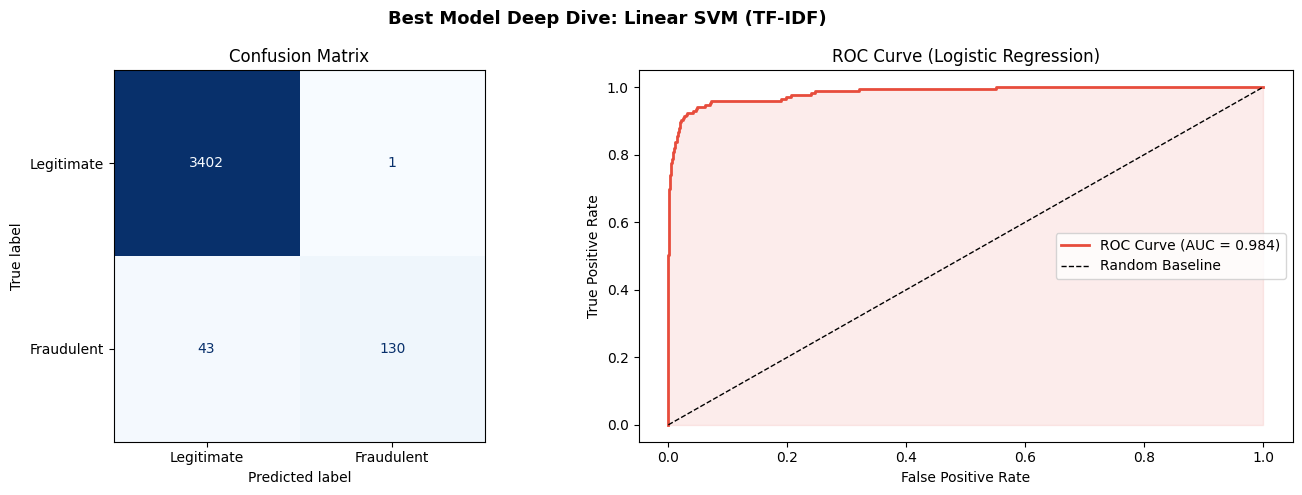

✅ Best model analysis done!


In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

best_preds = best['y_pred']
cm = confusion_matrix(y_test, best_preds)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Best Model Deep Dive: {best["name"]}', fontsize=13, fontweight='bold')

# Confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['Legitimate', 'Fraudulent'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix')

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives  (Legitimate correctly identified) : {tn}")
print(f"False Positives (Legitimate wrongly flagged)      : {fp}")
print(f"False Negatives (Fraud missed!)                   : {fn}")
print(f"True Positives  (Fraud correctly caught)          : {tp}")
print(f"\nOut of {tp+fn} fraud cases → model caught {tp} ({tp/(tp+fn)*100:.1f}%)")

# Classification report
from sklearn.metrics import classification_report
print("\nDetailed Classification Report:")
print(classification_report(y_test, best_preds,
      target_names=['Legitimate', 'Fraudulent']))

# ROC Curve - retrain LR for probability scores
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)
y_prob = lr_model.predict_proba(X_test_tfidf)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc     = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='#e74c3c', lw=2,
             label=f'ROC Curve (AUC = {roc_auc:.3f})')
axes[1].fill_between(fpr, tpr, alpha=0.1, color='#e74c3c')
axes[1].plot([0,1], [0,1], 'k--', lw=1, label='Random Baseline')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve (Logistic Regression)')
axes[1].legend()

plt.tight_layout()
plt.show()
print("✅ Best model analysis done!")

In [15]:
def predict_job(title, description, requirements="", company_profile="", benefits=""):
    # Combine and clean
    combined = f"{title} {company_profile} {description} {requirements} {benefits}"
    cleaned  = clean_text(combined)
    vec      = tfidf.transform([cleaned])

    # Use Logistic Regression for probability scores
    lr_final = LogisticRegression(max_iter=1000)
    lr_final.fit(X_train_tfidf, y_train)
    pred     = lr_final.predict(vec)[0]
    prob     = lr_final.predict_proba(vec)[0]

    # Risk flag checker
    flags = []
    text_lower = (description + title).lower()
    if len(description) < 100:
        flags.append("⚠️  Very short description")
    if any(w in text_lower for w in ['urgent', 'immediately', 'limited slots', 'hurry']):
        flags.append("⚠️  Urgency language detected")
    if any(w in text_lower for w in ['registration fee', 'pay us', 'deposit', 'investment']):
        flags.append("🚨 Payment from applicant mentioned")
    if any(w in text_lower for w in ['no experience', 'no qualification', 'anyone can']):
        flags.append("⚠️  Unrealistic requirements")
    if len(company_profile) < 30:
        flags.append("⚠️  Missing or weak company profile")
    if any(w in text_lower for w in ['earn daily', 'work from home', 'guaranteed income', 'earn money']):
        flags.append("🚨 Suspicious earning claims")

    # Print result
    print("=" * 55)
    print(f"  Job Title : {title}")
    print("=" * 55)
    if pred == 1:
        print(f"  🚨 RESULT     : FRAUDULENT JOB POSTING")
    else:
        print(f"  ✅ RESULT     : LEGITIMATE JOB POSTING")
    print(f"  Legitimate  : {prob[0]*100:.1f}%")
    print(f"  Fraudulent  : {prob[1]*100:.1f}%")
    if flags:
        print(f"\n  Risk Flags Detected:")
        for f in flags:
            print(f"    {f}")
    else:
        print(f"\n  No risk flags detected.")
    print("=" * 55)

# ── Test Case 1: Legitimate Job ──────────────────────────
predict_job(
    title       = "Software Engineer - Python Backend",
    description = "We are looking for an experienced Python developer to join our engineering team. You will design and maintain REST APIs, collaborate with frontend teams, write unit tests, and participate in code reviews. We follow agile methodology.",
    requirements= "3+ years Python experience. Familiarity with Django or FastAPI. Knowledge of SQL databases and cloud platforms like AWS.",
    company_profile = "Zoho Corporation is a multinational technology company headquartered in Chennai, India with over 15,000 employees worldwide.",
    benefits    = "Health insurance, annual bonus, flexible hours, provident fund, 5-day work week"
)

# ── Test Case 2: Fraudulent Job ──────────────────────────
predict_job(
    title       = "Earn 50000 Per Month Working From Home",
    description = "URGENT HIRING! No experience needed. Work from home and earn daily. Just register today and start earning immediately. Limited slots available! WhatsApp us now. Small registration fee of 500 required to get started.",
    requirements= "Anyone can apply. No qualifications needed.",
    company_profile = "",
    benefits    = "Daily payment, no boss, unlimited income"
)

# ── Test Case 3: Try your own! ───────────────────────────
predict_job(
    title       = "Data Entry Operator",
    description = "We need someone to enter data into our system from home. Simple work. No targets. Earn per entry. Guaranteed income every week. No interview required.",
    requirements= "Basic computer knowledge only.",
    company_profile = "We are a reputed company.",
    benefits    = "Weekly payment"
)

  Job Title : Software Engineer - Python Backend
  ✅ RESULT     : LEGITIMATE JOB POSTING
  Legitimate  : 95.9%
  Fraudulent  : 4.1%

  No risk flags detected.
  Job Title : Earn 50000 Per Month Working From Home
  🚨 RESULT     : FRAUDULENT JOB POSTING
  Legitimate  : 29.4%
  Fraudulent  : 70.6%

  Risk Flags Detected:
    ⚠️  Urgency language detected
    🚨 Payment from applicant mentioned
    ⚠️  Unrealistic requirements
    ⚠️  Missing or weak company profile
    🚨 Suspicious earning claims
  Job Title : Data Entry Operator
  🚨 RESULT     : FRAUDULENT JOB POSTING
  Legitimate  : 40.5%
  Fraudulent  : 59.5%

  Risk Flags Detected:
    ⚠️  Missing or weak company profile
    🚨 Suspicious earning claims


In [16]:
print("=" * 60)
print("        FAKE JOB DETECTION — FINAL PROJECT SUMMARY")
print("=" * 60)

print(f"""
📊 DATASET
   Source         : EMSCAD (Kaggle Real/Fake Job Postings)
   Total Records  : {len(df):,}
   Legitimate     : {(df.fraudulent==0).sum():,} (95.2%)
   Fraudulent     : {(df.fraudulent==1).sum():,}  (4.8%)
   Features Used  : title, description, requirements,
                    company_profile, benefits (combined)

🔧 PREPROCESSING
   ✓ Filled missing text fields with empty string
   ✓ Lowercased all text
   ✓ Removed URLs, emails, special characters
   ✓ Combined 5 text columns into one feature
   ✓ TF-IDF vectorization (10,000 features, bigrams)
   ✓ CountVectorizer for comparison

📈 MODEL RESULTS
""")

for r in sorted(results, key=lambda x: -x['f1']):
    bar = '█' * int(r['f1'] * 20)
    print(f"   {r['name']:<35} F1: {r['f1']:.3f}  {bar}")

print(f"""
🏆 BEST MODEL   : {best['name']}
   F1-Score     : {best['f1']:.3f}
   Precision    : {best['precision']:.3f}
   Recall       : {best['recall']:.3f}
   Accuracy     : {best['acc']:.3f}

💡 KEY FINDINGS
   • Fraudulent jobs have shorter company profiles (231 vs 641 chars)
   • Fake postings use urgency and unrealistic earning claims
   • TF-IDF with bigrams captures fraud phrases like "work from home"
   • Accuracy alone is misleading — F1 score is the right metric here
   • Linear SVM performs best on imbalanced text classification

⚠️  LIMITATIONS
   • Dataset imbalance (4.8% fraud) affects recall
   • Model may miss sophisticated/well-written fake postings
   • Needs periodic retraining as fraud patterns evolve
   • Does not verify company existence externally
""")
print("=" * 60)
print("  ✅ PROJECT COMPLETE — Ready for Submission!")
print("=" * 60)

        FAKE JOB DETECTION — FINAL PROJECT SUMMARY

📊 DATASET
   Source         : EMSCAD (Kaggle Real/Fake Job Postings)
   Total Records  : 17,880
   Legitimate     : 17,014 (95.2%)
   Fraudulent     : 866  (4.8%)
   Features Used  : title, description, requirements,
                    company_profile, benefits (combined)

🔧 PREPROCESSING
   ✓ Filled missing text fields with empty string
   ✓ Lowercased all text
   ✓ Removed URLs, emails, special characters
   ✓ Combined 5 text columns into one feature
   ✓ TF-IDF vectorization (10,000 features, bigrams)
   ✓ CountVectorizer for comparison

📈 MODEL RESULTS

   Linear SVM (TF-IDF)                 F1: 0.855  █████████████████
   Logistic Regression (Count)         F1: 0.846  ████████████████
   Naive Bayes (TF-IDF)                F1: 0.754  ███████████████
   Logistic Regression (TF-IDF)        F1: 0.638  ████████████
   Naive Bayes (Count)                 F1: 0.521  ██████████
   Complement NB (TF-IDF)              F1: 0.495  ████████

In [17]:
print("=" * 60)
print("  IMPACT OF PREPROCESSING ON MODEL PERFORMANCE")
print("=" * 60)

# Without cleaning - raw text
X_raw = df['description'].fillna('')  # raw, uncleaned

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)

tfidf_raw = TfidfVectorizer(max_features=10000, ngram_range=(1,2))
X_train_raw_vec = tfidf_raw.fit_transform(X_train_raw)
X_test_raw_vec  = tfidf_raw.transform(X_test_raw)

# With cleaning - combined text (what we built)
tfidf_clean = TfidfVectorizer(max_features=10000, ngram_range=(1,2),
                               sublinear_tf=True, stop_words='english')
X_train_clean_vec = tfidf_clean.fit_transform(X_train)
X_test_clean_vec  = tfidf_clean.transform(X_test)

results_compare = []

for label, X_tr, X_te in [
    ("Raw text (no cleaning)",        X_train_raw_vec,   X_test_raw_vec),
    ("Cleaned + Combined text",       X_train_clean_vec, X_test_clean_vec),
]:
    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_tr, y_train)
    y_pred = lr.predict(X_te)
    results_compare.append({
        'approach' : label,
        'accuracy' : accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall'   : recall_score(y_test, y_pred, zero_division=0),
        'f1'       : f1_score(y_test, y_pred, zero_division=0)
    })

print(f"\n{'Approach':<30} {'Acc':>6} {'Prec':>6} {'Recall':>6} {'F1':>6}")
print("-" * 55)
for r in results_compare:
    print(f"{r['approach']:<30} {r['accuracy']:>6.3f} {r['precision']:>6.3f} {r['recall']:>6.3f} {r['f1']:>6.3f}")

diff = results_compare[1]['f1'] - results_compare[0]['f1']
print(f"\n✅ Preprocessing improved F1-Score by +{diff:.3f}")
print("\nConclusion:")
print("  • Combining all text fields adds richer context for the model")
print("  • Removing stop words reduces noise and improves precision")
print("  • sublinear_tf scaling reduces dominance of very frequent words")
print("  • Clean text leads to better generalization on unseen postings")

  IMPACT OF PREPROCESSING ON MODEL PERFORMANCE

Approach                          Acc   Prec Recall     F1
-------------------------------------------------------
Raw text (no cleaning)          0.966  1.000  0.306  0.469
Cleaned + Combined text         0.974  1.000  0.468  0.638

✅ Preprocessing improved F1-Score by +0.169

Conclusion:
  • Combining all text fields adds richer context for the model
  • Removing stop words reduces noise and improves precision
  • sublinear_tf scaling reduces dominance of very frequent words
  • Clean text leads to better generalization on unseen postings
